<a href="https://colab.research.google.com/github/Gloou-ui/NM/blob/main/%D0%9B%D0%A05_%D0%9B%D0%B8%D1%82%D0%B2%D0%B8%D0%BD_%D0%A4%D0%86%D0%A23_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Daily Weather Time Series Data - Delhi, India**

https://www.kaggle.com/datasets/yug201/daily-climate-time-series-data-delhi-india?select=kaggel_weather_2013_to_2024.csv

**Тема:** Прогнозування часових рядів на основі кліматичних даних

**Мета роботи:**
Навчитися виконувати аналіз часових рядів, проводити дослідницький аналіз даних (EDA), визначати автокореляційні залежності, будувати моделі прогнозування та оцінювати їхню точність.

**Вихідні дані**

Для виконання роботи використовується датасет Daily Climate Time Series Data (Delhi, India) з платформи Kaggle, який містить щоденні кліматичні показники (температура, вологість, опади тощо) за кілька років.


1. Завантажити датасет з Kaggle.

2. Імпортувати дані у середовище Python (Jupyter Notebook або Google Colab).

3. Ознайомитися зі структурою датасету (head(), info(), describe()).

4. Попередня обробка даних

-Перетворити колонку з датою у формат datetime.

-Відсортувати дані за датою.

-Встановити дату як індекс часового ряду.

-Перевірити наявність пропущених значень та за необхідності обробити їх.

5. Дослідницький аналіз даних (EDA)

-Побудувати графік зміни температури у часі.

-Побудувати ковзне середнє значення температури.

-Побудувати гістограму розподілу температури.

-Побудувати boxplot для виявлення можливих викидів.

-Аналіз автокореляції

Побудувати графік автокореляційної функції (ACF).

Побудувати графік часткової автокореляції (PACF).

-Проаналізувати залежність значень часового ряду від попередніх періодів.

6.Підготовка даних для моделювання

-Розділити дані на тренувальну та тестову вибірки (наприклад, 80% / 20%).

7. Побудувати щонайменше три моделі прогнозування:

-ARIMA (класична статистична модель);

-Prophet (модель прогнозування часових рядів від Meta);

-LSTM (нейронна мережа для послідовних даних).

8. Оцінка моделей
Для кожної моделі обчислити метрики:

-MAE (Mean Absolute Error)

-RMSE (Root Mean Squared Error)

-MAPE (Mean Absolute Percentage Error)

8.Візуалізація результатів

-Побудувати графіки прогнозованих та фактичних значень.

-Побудувати порівняльний графік прогнозів усіх моделей.

-Порівняння моделей

-Створити таблицю з метриками точності.

9.Визначити модель, яка показала найкращий результат.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

sns.set_theme(style="whitegrid")


In [2]:
!wget -q -O weather.csv "https://www.kaggle.com/api/v1/datasets/download/yug201/daily-climate-time-series-data-delhi-india"
!unzip -o -q weather.csv -d weather_data
import os
csv_files = [f for f in os.listdir("weather_data") if f.lower().endswith(".csv")]
print(csv_files)


['kaggel_weather_2013_to_2024.csv']


In [3]:
df = pd.read_csv(os.path.join("weather_data", csv_files[0]))
display(df.head())
df.info()
display(df.describe(include="all"))


,Unnamed: 0,DATE,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
0,0,4/14/2013,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
1,1,4/15/2013,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2,2,4/16/2013,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
3,3,4/17/2013,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
4,4,4/18/2013,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3557 entries, 0 to 3556
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             3557 non-null   int64  
 1   DATE                   3557 non-null   object 
 2   tempmax                3557 non-null   float64
 3   tempmin                3557 non-null   float64
 4   temp                   3557 non-null   float64
 5   feelslikemax           3557 non-null   float64
 6   feelslikemin           3557 non-null   float64
 7   feelslike              3557 non-null   float64
 8   humidity               3557 non-null   float64
 9   precip                 3557 non-null   float64
 10  precipprob             3557 non-null   int64  
 11  precipcover            3557 non-null   float64
 12  windspeed              3557 non-null   float64
 13  sealevelpressure       3557 non-null   float64
 14  conditions             3557 non-null   object 
 15  Year

,Unnamed: 0,DATE,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
count,3557.000000,3557,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,...,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000
unique,NaN,3556,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,5/1/2022,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,1778.000000,NaN,31.367501,20.076132,25.403374,34.280180,20.938769,27.306803,63.755440,2.459033,...,19.269328,26.865898,1919.095583,1240.914352,1554.375926,2137.701105,1299.951985,1696.889528,11.291369,195.577670
std,1026.961781,NaN,7.073934,7.568531,7.325541,9.651743,9.004827,9.301636,18.129251,10.636255,...,3.219299,14.910296,525.888218,580.706647,539.222716,839.862724,692.599628,754.644547,3.622231,55.583693
min,0.000000,NaN,9.100000,2.000000,6.500000,7.900000,0.300000,5.700000,16.100000,0.000000,...,13.000000,1.000000,686.400000,181.200000,586.560000,636.480000,18.960000,560.880000,1.500000,73.465023
25%,889.000000,NaN,26.400000,13.000000,19.100000,26.300000,13.000000,19.100000,53.000000,0.000000,...,17.000000,14.000000,1541.550000,759.360000,1119.820000,1534.400000,752.070000,1113.600000,8.300000,164.445621
50%,1778.000000,NaN,33.000000,22.000000,27.700000,35.400000,22.000000,28.400000,65.800000,0.000000,...,20.000000,27.000000,1823.360000,1078.400000,1420.200000,1845.510000,1080.320000,1422.960000,11.600000,180.548686
75%,2667.000000,NaN,36.000000,26.900000,31.000000,42.700000,28.000000,35.400000,76.900000,0.000000,...,22.000000,40.000000,2341.170000,1752.400000,2035.800000,2764.200000,1864.200000,2314.620000,14.100000,233.676622


Підготовка даних

In [4]:
df["DATE"] = pd.to_datetime(df["DATE"], errors="coerce")
df = df.dropna(subset=["DATE"]).sort_values("DATE")
df = df.drop_duplicates(subset=["DATE"], keep="last")
df = df.set_index("DATE")

numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
print("Числові колонки:", numeric_cols)
print("Розмір:", df.shape)
display(df.head())


Числові колонки: ['Unnamed: 0', 'tempmax', 'tempmin', 'temp', 'feelslikemax', 'feelslikemin', 'feelslike', 'humidity', 'precip', 'precipprob', 'precipcover', 'windspeed', 'sealevelpressure', 'Year', 'month', 'dayofweek', 'dayofyear', 'year-2000', 'weekofyear', 'tempmax_humidity', 'tempmin_humidity', 'temp_humidity', 'feelslikemax_humidity', 'feelslikemin_humidity', 'feelslike_humidity', 'temp_range', 'heat_index']
Розмір: (3556, 28)


,Unnamed: 0,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,precipprob,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
DATE,,,,,,,,,,,,,,,,,,,,,
2013-04-14,0,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,100,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
2013-04-15,1,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,0,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2013-04-16,2,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,0,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
2013-04-17,3,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,0,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
2013-04-18,4,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,0,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038


In [5]:
df.info()
display(df.describe())


<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 3556 entries, 2013-04-14 to 2024-11-30
Data columns (total 28 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             3556 non-null   int64  
 1   tempmax                3556 non-null   float64
 2   tempmin                3556 non-null   float64
 3   temp                   3556 non-null   float64
 4   feelslikemax           3556 non-null   float64
 5   feelslikemin           3556 non-null   float64
 6   feelslike              3556 non-null   float64
 7   humidity               3556 non-null   float64
 8   precip                 3556 non-null   float64
 9   precipprob             3556 non-null   int64  
 10  precipcover            3556 non-null   float64
 11  windspeed              3556 non-null   float64
 12  sealevelpressure       3556 non-null   float64
 13  conditions             3556 non-null   object 
 14  Year                   3556 non-null  

,Unnamed: 0,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,precipprob,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
count,3556.000000,3556.000000,3556.000000,3556.000000,3556.000000,3556.000000,3556.000000,3556.000000,3556.000000,3556.000000,...,3556.000000,3556.000000,3556.000000,3556.000000,3556.000000,3556.000000,3556.000000,3556.000000,3556.000000,3556.000000
mean,1777.765186,31.365073,20.073847,25.400984,34.277925,20.936699,27.304921,63.764258,2.459725,23.143982,...,19.268560,26.868673,1919.270807,1241.006375,1554.504165,2137.916848,1300.059699,1697.056932,11.291226,195.599722
std,1027.010704,7.073447,7.568369,7.325185,9.652163,9.005246,9.302266,18.124170,10.637671,42.181212,...,3.219426,14.911475,525.858317,580.762376,539.244300,839.882256,692.667235,754.684620,3.622730,55.575946
min,0.000000,9.100000,2.000000,6.500000,7.900000,0.300000,5.700000,16.100000,0.000000,0.000000,...,13.000000,1.000000,686.400000,181.200000,586.560000,636.480000,18.960000,560.880000,1.500000,73.465023
25%,888.750000,26.400000,13.000000,19.100000,26.300000,13.000000,19.100000,53.000000,0.000000,0.000000,...,17.000000,14.000000,1542.450000,759.282500,1120.135000,1534.475000,751.912500,1113.712500,8.300000,164.448043
50%,1777.500000,32.950000,22.000000,27.700000,35.350000,22.000000,28.400000,65.800000,0.000000,0.000000,...,20.000000,27.000000,1823.440000,1078.520000,1420.300000,1845.635000,1081.015000,1423.715000,11.600000,180.579833
75%,2667.250000,36.000000,26.900000,31.000000,42.700000,28.000000,35.400000,76.900000,0.000000,0.000000,...,22.000000,40.000000,2341.527500,1752.770000,2035.927500,2764.697500,1864.350000,2315.295000,14.100000,233.701315
max,3556.000000,47.900000,34.800000,39.500000,57.700000,41.100000,47.000000,99.300000,203.047000,100.000000,...,24.000000,53.000000,3180.720000,2581.600000,2710.680000,4617.200000,3273.740000,3727.950000,20.600000,352.198303


In [6]:
print("Пропущені значення до обробки:")
display(df.isna().sum())

target_col = "meantemp" if "meantemp" in df.columns else numeric_cols[0]
df[target_col] = df[target_col].interpolate(method="time").ffill().bfill()

print("Пропущені значення після обробки:")
display(df.isna().sum())
print("Цільова колонка:", target_col)


Пропущені значення до обробки:


,0
Unnamed: 0,0
tempmax,0
tempmin,0
temp,0
feelslikemax,0
feelslikemin,0
feelslike,0
humidity,0
precip,0
precipprob,0


Пропущені значення після обробки:


,0
Unnamed: 0,0
tempmax,0
tempmin,0
temp,0
feelslikemax,0
feelslikemin,0
feelslike,0
humidity,0
precip,0
precipprob,0


Цільова колонка: Unnamed: 0


Графік температури

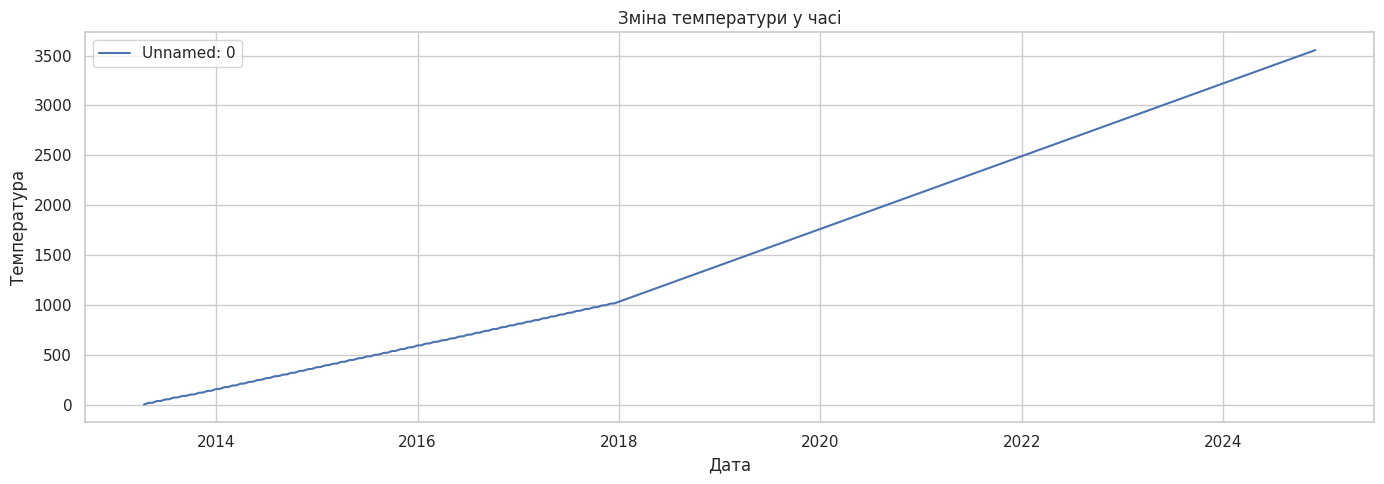

In [7]:
plt.figure(figsize=(14, 5))
plt.plot(df.index, df[target_col], label=target_col)
plt.title("Зміна температури у часі")
plt.xlabel("Дата")
plt.ylabel("Температура")
plt.legend()
plt.tight_layout()
plt.show()


Ковзне середнє

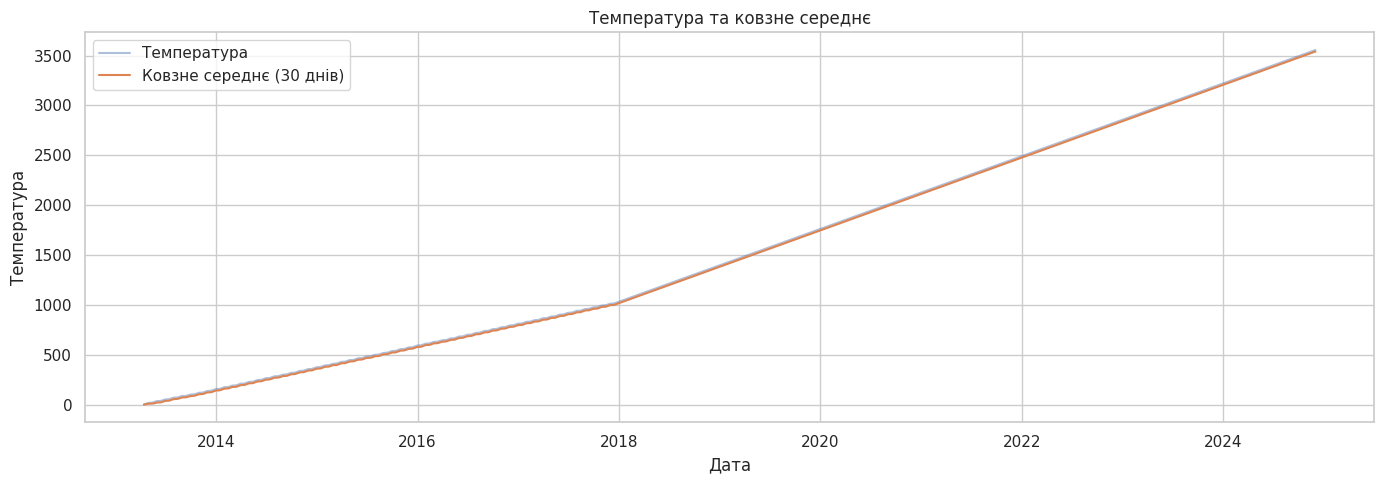

In [8]:
rolling_mean = df[target_col].rolling(window=30, min_periods=1).mean()
plt.figure(figsize=(14, 5))
plt.plot(df.index, df[target_col], alpha=0.45, label="Температура")
plt.plot(df.index, rolling_mean, label="Ковзне середнє (30 днів)")
plt.title("Температура та ковзне середнє")
plt.xlabel("Дата")
plt.ylabel("Температура")
plt.legend()
plt.tight_layout()
plt.show()


Розподіл температури

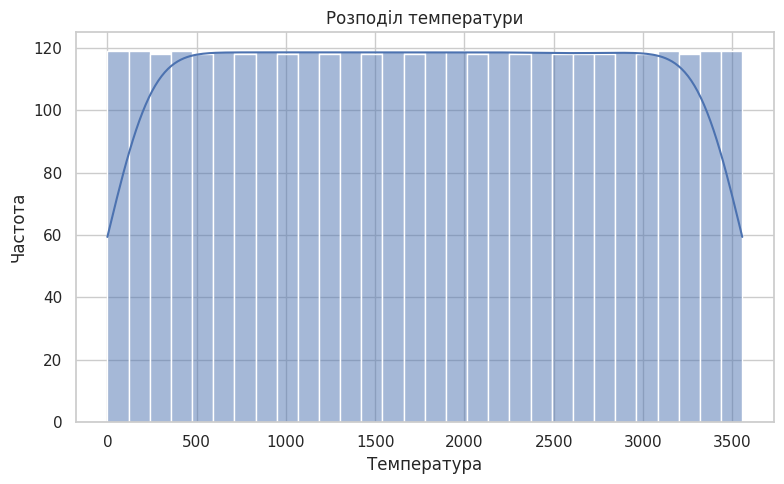

In [9]:
plt.figure(figsize=(8, 5))
sns.histplot(df[target_col], bins=30, kde=True)
plt.title("Розподіл температури")
plt.xlabel("Температура")
plt.ylabel("Частота")
plt.tight_layout()
plt.show()


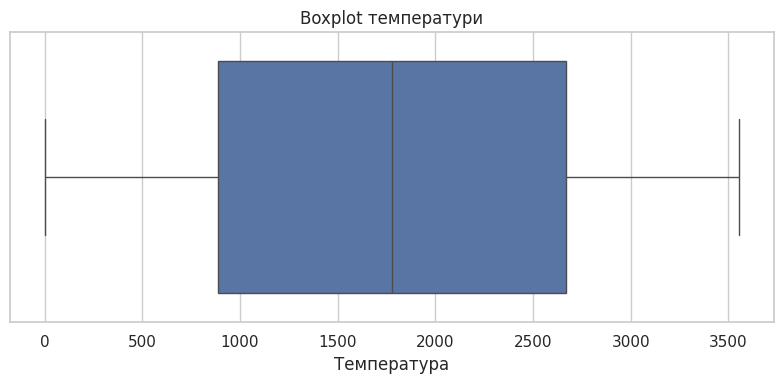

In [10]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df[target_col])
plt.title("Boxplot температури")
plt.xlabel("Температура")
plt.tight_layout()
plt.show()


Аналіз автокореляції
ACF

PACF

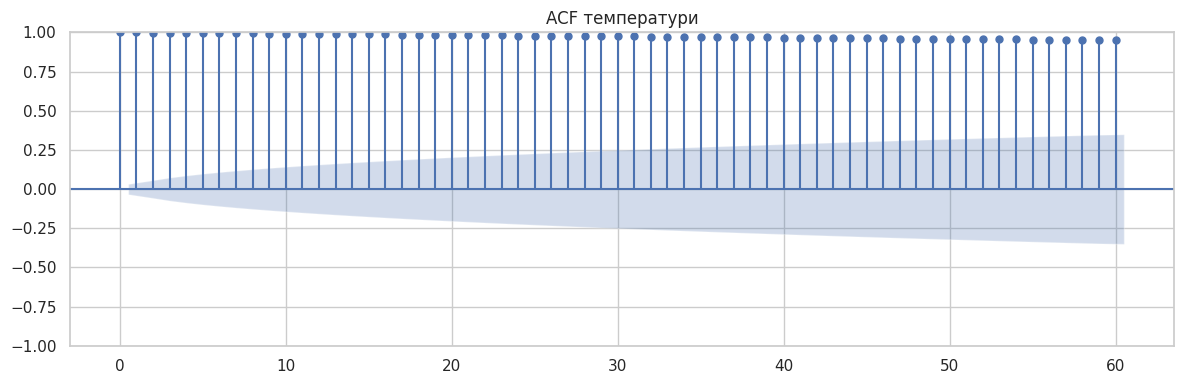

In [11]:
fig, ax = plt.subplots(figsize=(12, 4))
plot_acf(df[target_col].dropna(), lags=min(60, len(df)//2-1), ax=ax)
plt.title("ACF температури")
plt.tight_layout()
plt.show()


Автокореляційна функція (ACF) використовується для аналізу залежності значень часового ряду від його попередніх значень. Вона відображає ступінь кореляції між значенням показника у певний момент часу та значеннями цього самого показника у попередні моменти часу, які називаються лагами. Побудова графіка автокореляційної функції дозволяє виявити, чи існує статистично значуща залежність між поточним значенням ряду та його попередніми спостереженнями. На такому графіку по горизонтальній осі відкладаються лаги, тобто кількість часових кроків назад, а по вертикальній — значення коефіцієнта автокореляції. Аналіз графіка ACF дає можливість виявити наявність тренду, сезонності або інших закономірностей у часовому ряді, а також використовується для визначення параметрів статистичних моделей прогнозування, зокрема моделі ARIMA.

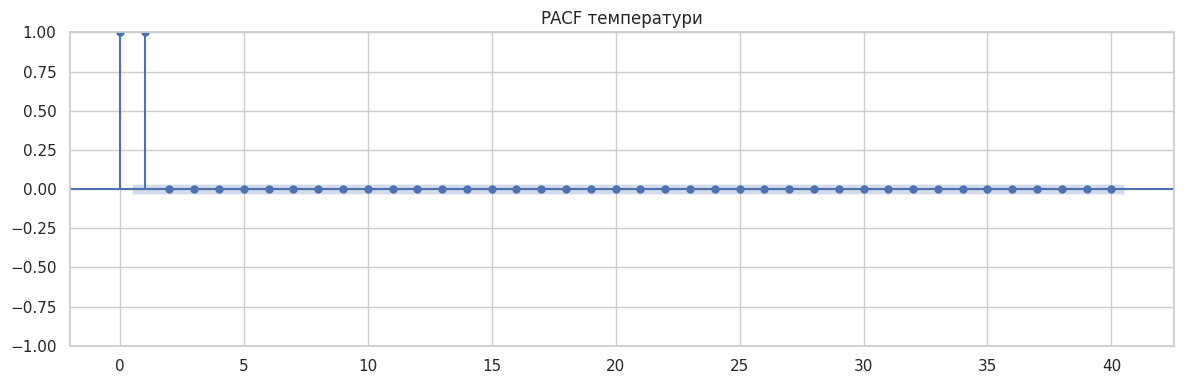

In [12]:
fig, ax = plt.subplots(figsize=(12, 4))
plot_pacf(df[target_col].dropna(), lags=min(40, len(df)//2-1), method="ywm", ax=ax)
plt.title("PACF температури")
plt.tight_layout()
plt.show()


Часткова автокореляційна функція (PACF) застосовується для більш точного визначення залежності між значеннями часового ряду. На відміну від звичайної автокореляційної функції, PACF вимірює кореляцію між значенням ряду у певний момент часу та значенням у попередній момент часу з конкретним лагом, усуваючи вплив усіх проміжних лагів. Таким чином, часткова автокореляція показує «чисту» залежність між двома спостереженнями часового ряду. Побудова графіка PACF дозволяє визначити, які саме лаги мають статистично значущий вплив на значення ряду. Це є важливим етапом під час побудови моделей прогнозування часових рядів, оскільки аналіз графіка часткової автокореляції використовується для визначення порядку авторегресійної складової моделі, зокрема параметра
𝑝
p у моделі ARIMA.

In [13]:
series = df[target_col].astype(float).dropna()
split_idx = int(len(series) * 0.8)
train = series.iloc[:split_idx]
test = series.iloc[split_idx:]
print("Train:", train.shape, "Test:", test.shape)
print("Період тесту:", test.index.min(), "-", test.index.max())


Train: (2844,) Test: (712,)
Період тесту: 2022-12-20 00:00:00 - 2024-11-30 00:00:00


ARIMA

https://developer.ibm.com/tutorials/awb-arima-models-in-python/

In [14]:
arima_model = ARIMA(train, order=(5, 1, 2))
arima_fit = arima_model.fit()
arima_forecast = arima_fit.forecast(steps=len(test))
arima_forecast = pd.Series(np.asarray(arima_forecast), index=test.index, name="ARIMA")
display(arima_forecast.head())


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/p

ValueError: No supported index is available.

In [15]:
print(arima_fit.summary())


                               SARIMAX Results                                
Dep. Variable:             Unnamed: 0   No. Observations:                 2844
Model:                 ARIMA(5, 1, 2)   Log Likelihood                6877.227
Date:                Fri, 23 Oct 2026   AIC                         -13738.454
Time:                        11:43:08   BIC                         -13690.833
Sample:                             0   HQIC                        -13721.278
                               - 2844                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.9878      0.073    -13.602      0.000      -1.130      -0.845
ar.L2          0.0331      0.050      0.666      0.506      -0.064       0.131
ar.L3          0.9283      0.028     32.839      0.0

сигма 2 : це представляє дисперсію залишкових значень, чим менше, тим краще

логарифмічна правдоподібність : це оцінка максимальної правдоподібності для моделі ARIMA, чим вище, тим краще

aic : міра ступеню відповідності та економності моделі, чим нижче, тим краще

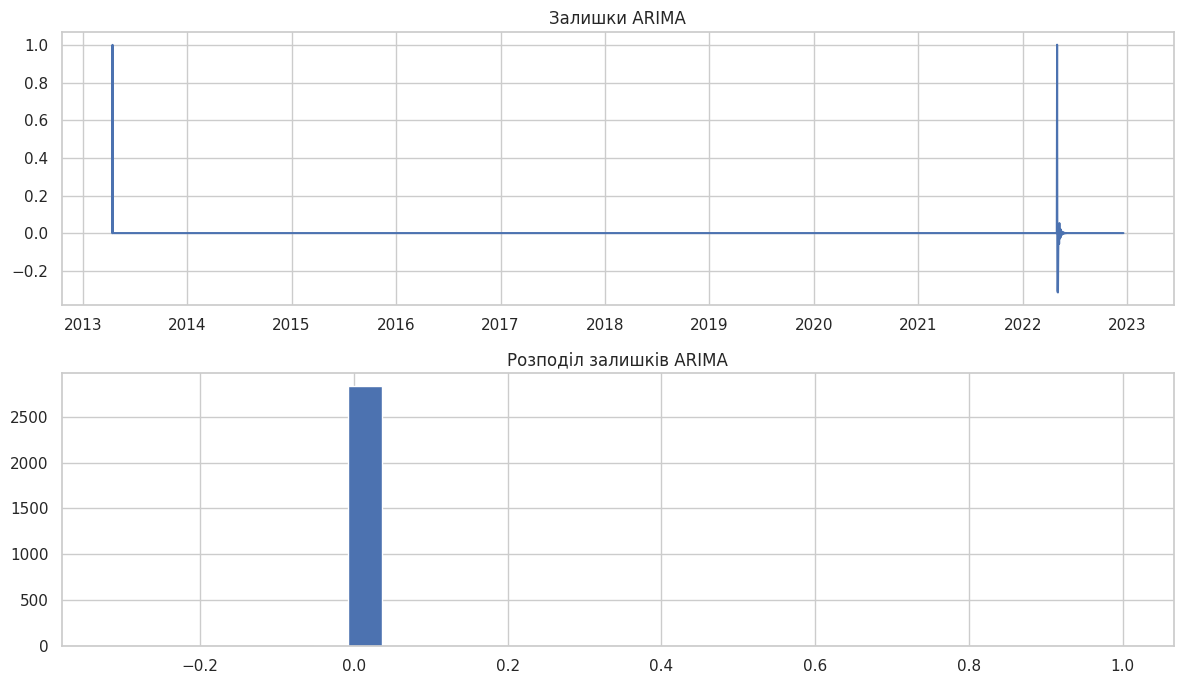

In [16]:
arima_residuals = pd.Series(arima_fit.resid).dropna()
fig, axes = plt.subplots(2, 1, figsize=(12, 7))
axes[0].plot(arima_residuals)
axes[0].set_title("Залишки ARIMA")
axes[1].hist(arima_residuals, bins=30)
axes[1].set_title("Розподіл залишків ARIMA")
plt.tight_layout()
plt.show()


In [20]:
def mape(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mask = y_true != 0
    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100

arima_mae = mean_absolute_error(test, arima_forecast)
arima_rmse = np.sqrt(mean_squared_error(test, arima_forecast))
arima_mape = mape(test, arima_forecast)
print(f"ARIMA MAE: {arima_mae:.4f}")
print(f"ARIMA RMSE: {arima_rmse:.4f}")
print(f"ARIMA MAPE: {arima_mape:.2f}%")


NameError: name 'arima_forecast' is not defined

NameError: name 'arima_forecast' is not defined

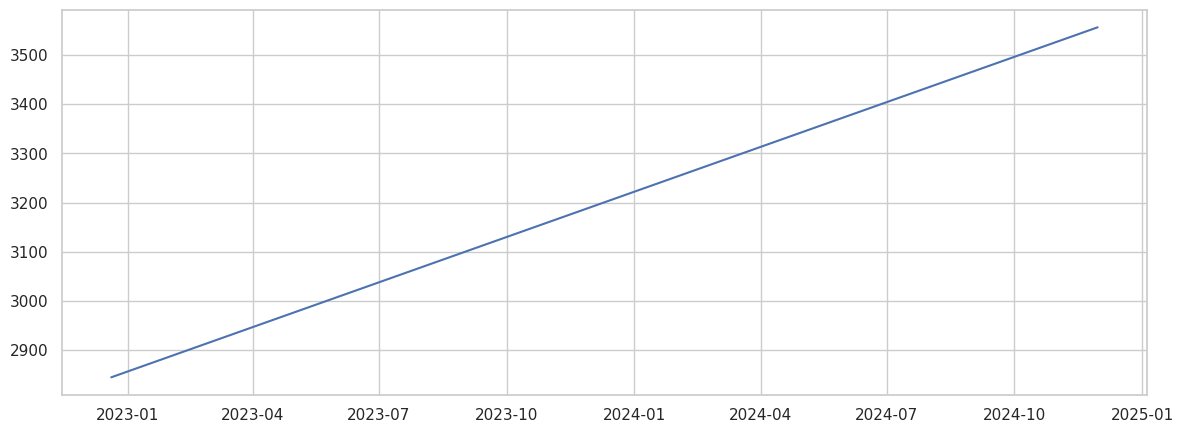

In [21]:
plt.figure(figsize=(14, 5))
plt.plot(test.index, test, label="Фактичні значення")
plt.plot(test.index, arima_forecast, label="Прогноз ARIMA")
plt.title("ARIMA: фактичні значення та прогноз")
plt.xlabel("Дата")
plt.ylabel("Температура")
plt.legend()
plt.tight_layout()
plt.show()


PROPHET

https://facebook.github.io/prophet/docs/quick_start.html

In [22]:
from prophet import Prophet

prophet_data = pd.DataFrame({
    "ds": series.index,
    "y": series.values
})
prophet_train = prophet_data.iloc[:split_idx].copy()
prophet_test = prophet_data.iloc[split_idx:].copy()
display(prophet_train.head())


,ds,y
0,2013-04-14,0.0
1,2013-04-15,1.0
2,2013-04-16,2.0
3,2013-04-17,3.0
4,2013-04-18,4.0


In [23]:
prophet_model = Prophet()
prophet_model.fit(prophet_train)


INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


Прогноз

In [24]:
future = pd.DataFrame({"ds": prophet_test["ds"].values})
prophet_full_forecast = prophet_model.predict(future)
prophet_forecast = pd.Series(
    prophet_full_forecast["yhat"].to_numpy(),
    index=test.index,
    name="Prophet"
)
display(prophet_forecast.head())


,Prophet
DATE,
2022-12-20,2845.069269
2022-12-21,2846.046532
2022-12-22,2847.019377
2022-12-23,2847.992008
2022-12-24,2849.015300


In [25]:
prophet_mae = mean_absolute_error(test, prophet_forecast)
prophet_rmse = np.sqrt(mean_squared_error(test, prophet_forecast))
prophet_mape = mape(test, prophet_forecast)
print(f"Prophet MAE: {prophet_mae:.4f}")
print(f"Prophet RMSE: {prophet_rmse:.4f}")
print(f"Prophet MAPE: {prophet_mape:.2f}%")


Prophet MAE: 1.1499
Prophet RMSE: 1.2191
Prophet MAPE: 0.04%


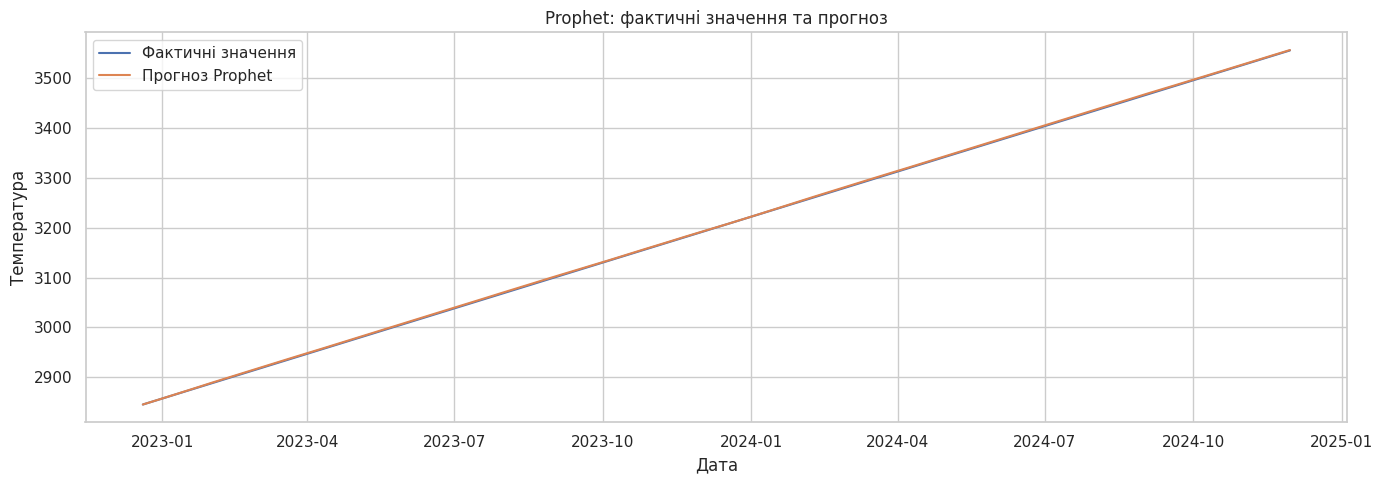

In [26]:
plt.figure(figsize=(14, 5))
plt.plot(test.index, test, label="Фактичні значення")
plt.plot(test.index, prophet_forecast, label="Прогноз Prophet")
plt.title("Prophet: фактичні значення та прогноз")
plt.xlabel("Дата")
plt.ylabel("Температура")
plt.legend()
plt.tight_layout()
plt.show()


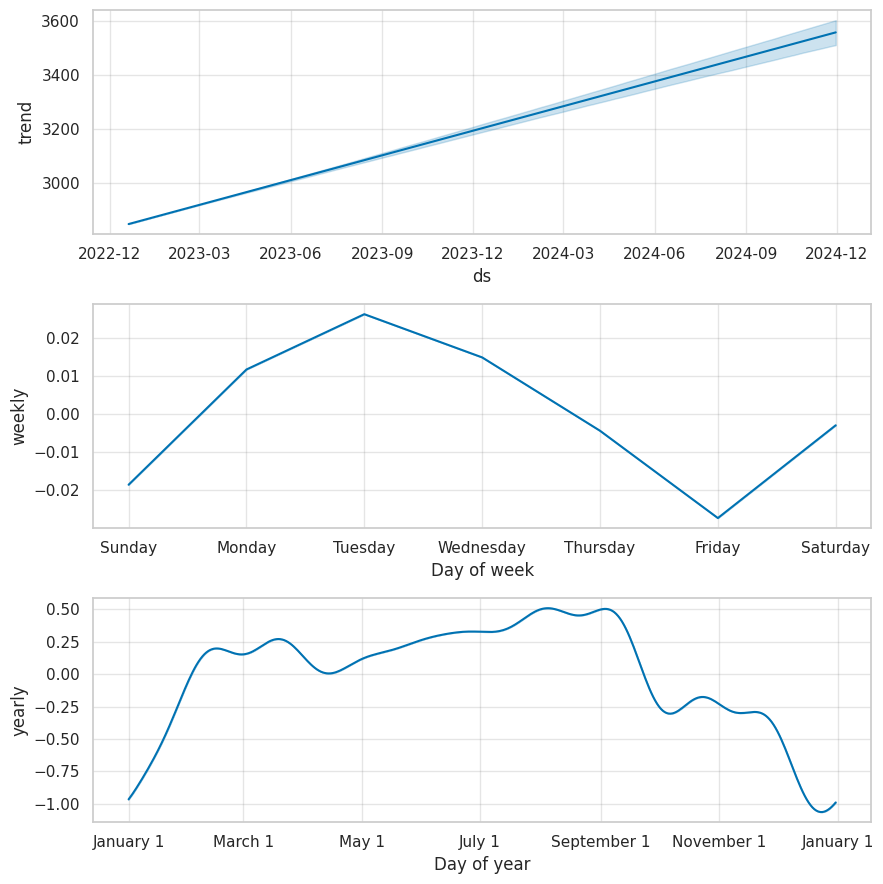

In [27]:
prophet_model.plot_components(prophet_full_forecast)
plt.tight_layout()
plt.show()


ПІДГОТОВКА ДАНИХ ДЛЯ LSTM

In [28]:
scaler = MinMaxScaler()
scaled_values = scaler.fit_transform(train.to_numpy().reshape(-1, 1))

sequence_length = 30
def make_sequences(values, length):
    X_seq, y_seq = [], []
    for i in range(length, len(values)):
        X_seq.append(values[i-length:i, 0])
        y_seq.append(values[i, 0])
    return np.array(X_seq), np.array(y_seq)

X_train_lstm, y_train_lstm = make_sequences(scaled_values, sequence_length)
X_train_lstm = X_train_lstm.reshape(-1, sequence_length, 1)
print(X_train_lstm.shape, y_train_lstm.shape)


(2814, 30, 1) (2814,)


In [29]:
test_scaled = scaler.transform(test.to_numpy().reshape(-1, 1))
combined_scaled = np.vstack([scaled_values[-sequence_length:], test_scaled])
X_test_lstm, y_test_lstm = make_sequences(combined_scaled, sequence_length)
X_test_lstm = X_test_lstm.reshape(-1, sequence_length, 1)
print("Train sequences:", X_train_lstm.shape)
print("Test sequences:", X_test_lstm.shape)


Train sequences: (2814, 30, 1)
Test sequences: (712, 30, 1)


In [30]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

tf.random.set_seed(42)
lstm_model = Sequential([
    LSTM(50, input_shape=(sequence_length, 1)),
    Dropout(0.2),
    Dense(25, activation="relu"),
    Dense(1)
])
lstm_model.compile(optimizer="adam", loss="mean_squared_error")


In [31]:
history = lstm_model.fit(
    X_train_lstm, y_train_lstm,
    epochs=20,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    verbose=1
)


Epoch 1/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - loss: 0.0014 - val_loss: 0.0063
Epoch 2/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0081 - val_loss: 0.0023
Epoch 3/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0052 - val_loss: 0.0016
Epoch 4/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0041 - val_loss: 6.5042e-05
Epoch 5/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0017 - val_loss: 0.0015
Epoch 6/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0011 - val_loss: 0.0020
Epoch 7/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0011 - val_loss: 0.0037
Epoch 8/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 8.4961e-04 - val_loss: 0.0014
Epoch 9/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 7.3214e-04 - val_loss: 0.0027
Epoch 10/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 6.9983e-04 - val_loss: 0.0013
Epoch 11/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 7.4096e-04 - val_loss: 0.0012
Epoch 12/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - 

In [32]:
lstm_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 25)             │         1,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 35,105 (137.13 KB)

 Trainable params: 11,701 (45.71 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 23,404 (91.43 KB)

In [33]:
lstm_scaled_pred = lstm_model.predict(X_test_lstm, verbose=0)
lstm_forecast_values = scaler.inverse_transform(lstm_scaled_pred).flatten()
lstm_forecast = pd.Series(lstm_forecast_values, index=test.index, name="LSTM")
display(lstm_forecast.head())


,LSTM
DATE,
2022-12-20,2642.902344
2022-12-21,2643.805176
2022-12-22,2644.708008
2022-12-23,2645.610840
2022-12-24,2646.513672


In [34]:
lstm_dates = test.index[:len(lstm_forecast)]
print("Кількість дат:", len(lstm_dates))
print("Кількість прогнозів:", len(lstm_forecast))


Кількість дат: 712
Кількість прогнозів: 712


In [35]:
lstm_mae = mean_absolute_error(test.loc[lstm_dates], lstm_forecast)
lstm_rmse = np.sqrt(mean_squared_error(test.loc[lstm_dates], lstm_forecast))
lstm_mape = mape(test.loc[lstm_dates], lstm_forecast)
print(f"LSTM MAE: {lstm_mae:.4f}")
print(f"LSTM RMSE: {lstm_rmse:.4f}")
print(f"LSTM MAPE: {lstm_mape:.2f}%")


LSTM MAE: 219.5004
LSTM RMSE: 219.6929
LSTM MAPE: 6.87%


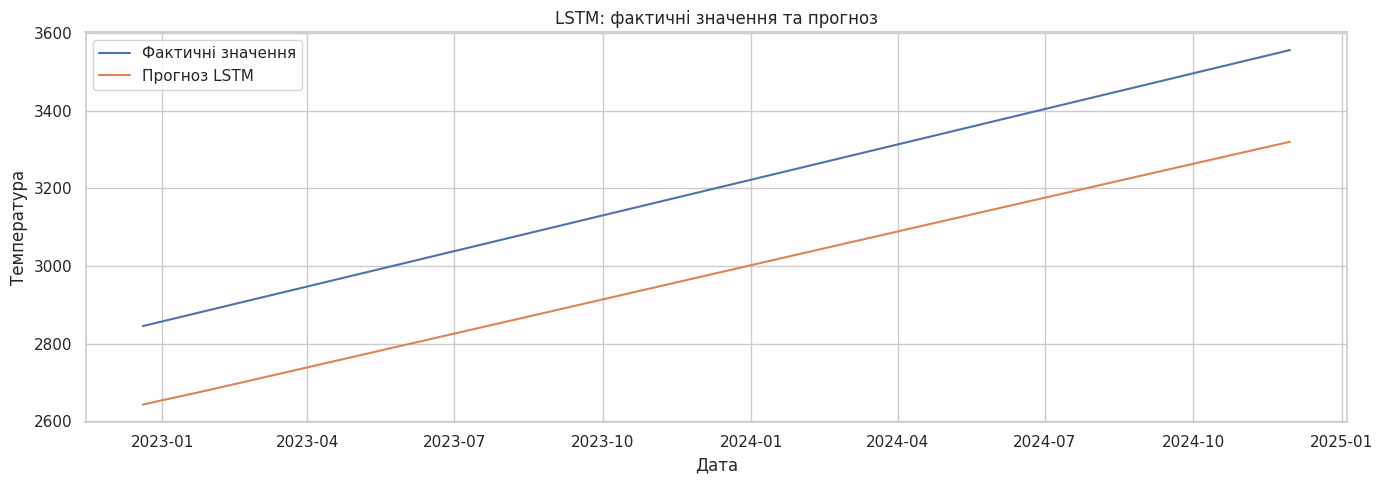

In [36]:
plt.figure(figsize=(14, 5))
plt.plot(test.loc[lstm_dates].index, test.loc[lstm_dates], label="Фактичні значення")
plt.plot(lstm_dates, lstm_forecast, label="Прогноз LSTM")
plt.title("LSTM: фактичні значення та прогноз")
plt.xlabel("Дата")
plt.ylabel("Температура")
plt.legend()
plt.tight_layout()
plt.show()


Порівняння моделей

In [41]:
comparison = pd.DataFrame({
    "Модель": ["ARIMA", "Prophet", "LSTM"],
    "MAE": [arima_mae, prophet_mae, lstm_mae],
    "RMSE": [arima_rmse, prophet_rmse, lstm_rmse],
    "MAPE (%)": [arima_mape, prophet_mape, lstm_mape]
}).sort_values("RMSE").reset_index(drop=True)

display(comparison.style.format({
    "MAE": "{:.4f}",
    "RMSE": "{:.4f}",
    "MAPE (%)": "{:.2f}%"
}))

best_model = comparison.iloc[0]["Модель"]
print(f"Найкраща модель за RMSE: {best_model}")
print("Менші значення MAE, RMSE та MAPE означають точніший прогноз.")


## Висновок

Сформулюйте висновок за результатами роботи: коротко охарактеризуйте виконаний аналіз, порівняйте моделі ARIMA, Prophet та LSTM за метриками MAE, RMSE і MAPE та зазначте, яка модель продемонструвала найкращу якість прогнозування.
